# UTS Praktikum Visi Komputer — Tema 7
## Penghitung Butir (Beras, Biji Kopi, atau Kacang)

**Kelompok 07** · Mini project pipeline Visi Komputer (Praktikum 1–5)

Notebook ini berisi pipeline lengkap Tema 7: menghitung butir pada foto
butiran yang ditabur di atas latar polos, lalu memisahkan **butir utuh** dan
**butir patah/kecil** berdasarkan ukuran.

> Notebook tetap bisa dijalankan (*Restart & Run All*) walaupun folder
> `dataset/` masih kosong. Tabel evaluasi dan grafik akan terisi otomatis
> setelah foto dan `dataset/ground_truth.csv` dilengkapi.

## Peta materi praktikum (P1–P5)

| Prak | Materi | Dipakai di | Contoh di notebook |
|---|---|---|---|
| **P1** | Python dasar: variabel, list, dictionary, kondisi, loop, fungsi | Seluruh notebook | setiap tahap ditulis sebagai fungsi (`resize_longest`, `segment`, `extract_objects`, ...) |
| **P2** | OpenCV I/O: `imread`, `imwrite`, menampilkan banyak gambar dengan matplotlib | Bagian 3 & luaran | `imread_unicode()`, `cv2.imwrite()` ke `output/`, figure panel per tahap |
| **P3** | Konversi warna (Gray), histogram, thresholding (Otsu/adaptive), resize | Tahap 2, 5, 10 | `cvtColor` → gray, `resize_longest`, Otsu & adaptive, `plot_area_histogram` |
| **P4** | Blur (median, Gaussian), kontur, `boundingRect`, `minAreaRect`, `convexHull` | Tahap 3, 4, 6, 7, 9 | `apply_illum_norm` (Gaussian), `apply_blur` (median), `findContours` + `contourArea`, `minAreaRect`, `convexHull` (solidity) |
| **P5** | Fitur & matching (SIFT/ORB, BFMatcher, homografi, warpPerspective) | — | tidak diperlukan untuk tema penghitung butir (segmentasi + kontur sudah cukup) |

> Operasi morfologi (open/close 3×3) dipakai sebagai **penunjang** untuk merapikan mask biner.

## 1. Identitas

Ubah data di bawah ini sebelum dikumpulkan. Tabel pembagian tugas ini juga
wajib dicantumkan di laporan (bagian 7).

In [57]:
# ============================================================
# 1. IDENTITAS KELOMPOK 
# ============================================================
KELOMPOK = "07"
TEMA = "Tema 7 Penghitung Butir (Beras, Biji Kopi, atau Kacang)"
JENIS_BUTIR = "kacang ijo"        # "beras", "kopi", atau "kacang"

ANGGOTA = [
    # (Nama, NIM, Tahap/bagian yang dikerjakan)
    ("Rahiqul Munadhil", "NPM 2408017010049"),
    ("Niswatul Azimah", "NPM 2408107010003"),
    ("Muhammad Irfan Qadafi", "NPM 24080107010054 "),
    ("Muhammad Nuril Alam", "NPM 2408107010081"),
]

print("=" * 66)
print(f"UTS Praktikum Visi Komputer — Kelompok {KELOMPOK}")
print(TEMA)
print("Jenis butir :", JENIS_BUTIR)
print("=" * 66)
for i, (nama, nim) in enumerate(ANGGOTA, 1):
    print(f"{i}. {nama:22s} {nim:12s}")

UTS Praktikum Visi Komputer — Kelompok 07
Tema 7 Penghitung Butir (Beras, Biji Kopi, atau Kacang)
Jenis butir : kacang ijo
1. Rahiqul Munadhil       NPM 2408017010049
2. Niswatul Azimah        NPM 2408107010003
3. Muhammad Irfan Qadafi  NPM 24080107010054 
4. Muhammad Nuril Alam    NPM 2408107010081


## 2. Import dan fungsi bantu

Setiap tahap pipeline ditulis sebagai fungsi Python terpisah (ketentuan P1),
sehingga mudah diuji, dipresentasikan, dan dijelaskan saat tanya jawab.

In [34]:
import csv
import time
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["axes.grid"] = False

DATASET_DIR = Path("dataset")
OUTPUT_DIR = Path("output")
GT_PATH = DATASET_DIR / "ground_truth.csv"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Folder kerja :", Path.cwd())
print("Dataset      :", DATASET_DIR.resolve())
print("Output       :", OUTPUT_DIR.resolve())
print("OpenCV       :", cv2.__version__)

Folder kerja : d:\New folder (11)\UTS_VisKom_Kelompok07
Dataset      : D:\New folder (11)\UTS_VisKom_Kelompok07\dataset
Output       : D:\New folder (11)\UTS_VisKom_Kelompok07\output
OpenCV       : 4.12.0


In [ ]:
# Parameter pipeline — nilai awal
PARAMS = {
    "resize_max": 1000,          # sisi terpanjang citra (aturan: 800-1200 px)
    "illum_norm": True,          # normalisasi pencahayaan sebelum threshold
    "illum_sigma": 25,           # sigma blur besar untuk normalisasi cahaya
    "blur_method": "median",     # "median" | "gaussian" | "none"
    "ksize": 5,                  # ukuran kernel blur (harus ganjil)
    "threshold_method": "otsu",  # "otsu" | "adaptive"
    "adaptive_block": 51,        # blockSize adaptive (ganjil, > 1)
    "adaptive_C": 7,             # konstanta C adaptive threshold
    "invert": "auto",            # "auto" | True | False
    "min_area": 40,              # luas minimum kontur (px^2) setelah resize
    "max_area_ratio": 0.10,      # kontur > 10% luas citra diabaikan
    "classify_by": "area",       # "area" | "length" (pemisahan utuh/patah)
    "calib_factor": 0.65,        # ambang = calib_factor x median luas butir ideal
    "split_min_ratio": None,     # pengaman k-means bila tanpa kalibrasi
    "min_cluster_frac": 0.08,    # tiap klaster minimal 8% objek
    "manual_threshold": None,    # diisi otomatis oleh sel kalibrasi
    "area_reference": None,      # median luas butir ideal (diisi sel kalibrasi)
}

print("Parameter aktif:")
for key, value in PARAMS.items():
    print(f"  {key:18s}: {value}")

Parameter aktif:
  resize_max        : 1000
  illum_norm        : True
  illum_sigma       : 25
  blur_method       : median
  ksize             : 5
  threshold_method  : otsu
  adaptive_block    : 51
  adaptive_C        : 7
  invert            : auto
  min_area          : 40
  max_area_ratio    : 0.1
  classify_by       : area
  calib_factor      : 0.65
  split_min_ratio   : None
  min_cluster_frac  : 0.08
  manual_threshold  : None
  area_reference    : None


In [36]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
CONDITION_ORDER = ["ideal", "cahaya", "rusak", "sudut", "sulit"]


def imread_unicode(path):
    """Membaca citra, termasuk path dengan karakter non-ASCII."""
    path = str(path)
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        try:
            buf = np.fromfile(path, dtype=np.uint8)
            img = cv2.imdecode(buf, cv2.IMREAD_COLOR)
        except Exception:
            img = None
    return img


def resize_longest(img, target=1000):
    """Perkecil citra agar sisi terpanjang <= target (tidak memperbesar)."""
    h, w = img.shape[:2]
    scale = float(target) / float(max(h, w))
    if scale < 1.0:
        img = cv2.resize(
            img,
            (int(round(w * scale)), int(round(h * scale))),
            interpolation=cv2.INTER_AREA,
        )
    return img


def apply_blur(gray, method="median", ksize=5):
    """Blur untuk menekan noise sebelum thresholding."""
    k = int(ksize)
    if k % 2 == 0:
        k += 1
    if method == "median":
        return cv2.medianBlur(gray, k)
    if method == "gaussian":
        return cv2.GaussianBlur(gray, (k, k), 0)
    if method == "none":
        return gray.copy()
    raise ValueError(f"blur_method tidak dikenal: {method}")


def apply_illum_norm(gray, sigma=25, target=180):
    """
    Normalisasi pencahayaan (flat-field): bagi citra dengan versi blur besar
    sehingga gradien cahaya/bayangan yang landai ikut terhapus dan Otsu
    tetap dapat memisahkan butir dari latar walau cahaya tidak merata.
    """
    bg = cv2.GaussianBlur(gray.astype(np.float32), (0, 0), sigmaX=float(sigma))
    bg = np.maximum(bg, 1.0)
    norm = gray.astype(np.float32) / bg
    norm = np.clip(norm * float(target), 0, 255).astype(np.uint8)
    return norm


def auto_invert(mask):
    """
    True jika kelas putih pada mask justru latar.
    Aturan: butir selalu MINORITAS piksel, jadi jika kelas putih menutupi
    > 55% citra, putih adalah latar dan mask harus di-invert.
    (Aturan tepi citra tidak dipakai karena vignetting pencahayaan HP
    membuat tepi citra gelap walau latar terang.)
    """
    white_ratio = float((mask > 0).mean())
    if white_ratio >= 0.55:
        return True
    if white_ratio <= 0.45:
        return False
    return JENIS_BUTIR.lower() in ("kopi", "kacang", "kacang hijau", "kacang tanah")


def segment(gray, method="otsu", adaptive_block=51, adaptive_C=7,
            invert="auto", morph=True):
    """Segmentasi butir (foreground putih) menjadi mask biner 0/255."""
    if method == "otsu":
        _, mask = cv2.threshold(
            gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )
    elif method == "adaptive":
        block = int(adaptive_block)
        if block % 2 == 0:
            block += 1
        block = max(3, block)
        mask = cv2.adaptiveThreshold(
            gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
            cv2.THRESH_BINARY, block, float(adaptive_C),
        )
    else:
        raise ValueError(f"threshold_method tidak dikenal: {method}")

    if invert == "auto":
        if auto_invert(mask):
            mask = cv2.bitwise_not(mask)
    elif bool(invert):
        mask = cv2.bitwise_not(mask)

    if morph:
        kernel = np.ones((3, 3), np.uint8)
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel, iterations=1)
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=1)
    return mask

In [37]:
def extract_objects(mask, min_area=40, max_area_ratio=0.05):
    """
    Cari kontur butir dan hitung fiturnya:
    luas (contourArea), panjang & lebar (minAreaRect), solidity.
    """
    contours, _ = cv2.findContours(
        mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    h, w = mask.shape[:2]
    max_area = max_area_ratio * h * w
    objects = []

    for contour in contours:
        area = float(cv2.contourArea(contour))
        if area < min_area or area > max_area:
            continue

        rect = cv2.minAreaRect(contour)          # ((cx, cy), (w, h), angle)
        rw, rh = rect[1]
        if rw <= 0 or rh <= 0:
            continue

        length = float(max(rw, rh))
        width = float(min(rw, rh))
        hull_area = float(cv2.contourArea(cv2.convexHull(contour)))
        solidity = area / hull_area if hull_area > 0 else 0.0
        x, y, bw, bh = cv2.boundingRect(contour)

        objects.append({
            "contour": contour,
            "area": area,
            "length": length,
            "width": width,
            "aspect": length / max(width, 1e-6),
            "solidity": solidity,
            "rect": rect,
            "bbox": (x, y, bw, bh),
            "center": (int(rect[0][0]), int(rect[0][1])),
        })

    return objects

In [38]:
def _kmeans_1d(values, iters=60):
    """K-means 1 dimensi untuk 2 klaster (implementasi numpy)."""
    v = np.asarray(values, dtype=np.float64).reshape(-1, 1)
    centers = np.array([[float(v.min())], [float(v.max())]], dtype=np.float64)
    labels = np.zeros(len(v), dtype=int)

    for _ in range(iters):
        dist = np.abs(v - centers.reshape(1, 2))
        new_labels = np.argmin(dist, axis=1)
        if np.array_equal(new_labels, labels):
            break
        labels = new_labels
        for j in range(2):
            if np.any(labels == j):
                centers[j, 0] = float(v[labels == j].mean())

    return centers.ravel(), labels


def classify_objects(objects, by="area", manual_threshold=None,
                     split_min_ratio=None, min_cluster_frac=0.08):
    """
    Pisahkan butir utuh vs patah.

    Utama: jika manual_threshold diisi (hasil kalibrasi dari kondisi ideal),
    klasifikasi hanya membandingkan luas/panjang objek dengan ambang tetap.

    Fallback: bila tanpa kalibrasi, dipakai 2 klaster k-means pada log(luas)
    atau log(panjang); klaster bernilai lebih besar = butir utuh. Pengaman:
    - jika rasio kedua pusat klaster < split_min_ratio, semua dianggap utuh
      (menghindari perpecahan palsu saat semua butir sebenarnya utuh);
    - jika salah satu klaster < min_cluster_frac, split ditolak.
    """
    if not objects:
        return None, {"split": False, "reason": "tidak ada objek", "ratio": None}

    if by == "area":
        values = np.array([o["area"] for o in objects], dtype=np.float64)
        auto_ratio = 1.6
    elif by == "length":
        values = np.array([o["length"] for o in objects], dtype=np.float64)
        auto_ratio = 1.25
    else:
        raise ValueError("classify_by harus 'area' atau 'length'")

    if manual_threshold is not None:
        threshold = float(manual_threshold)
        for obj, value in zip(objects, values):
            obj["whole"] = bool(value >= threshold)
        return threshold, {
            "split": True, "reason": "ambang kalibrasi", "ratio": None
        }

    if len(values) < 4 or np.isclose(values.min(), values.max()):
        for obj in objects:
            obj["whole"] = True
        return None, {
            "split": False, "reason": "objek terlalu sedikit/seragam",
            "ratio": None,
        }

    logv = np.log1p(values)
    centers, labels = _kmeans_1d(logv)
    low = float(min(centers))
    high = float(max(centers))
    ratio = float(np.expm1(high) / max(np.expm1(low), 1e-6))
    frac_low = float(np.mean(labels == int(np.argmin(centers))))
    min_ratio = float(split_min_ratio) if split_min_ratio is not None else auto_ratio

    if ratio < min_ratio or not (min_cluster_frac <= frac_low <= 1 - min_cluster_frac):
        for obj in objects:
            obj["whole"] = True
        return None, {
            "split": False,
            "reason": f"rasio {ratio:.2f} < {min_ratio:.2f} / klaster tidak seimbang",
            "ratio": ratio,
        }

    threshold = float(np.expm1((low + high) / 2.0))
    for obj, value in zip(objects, values):
        obj["whole"] = bool(value >= threshold)
    return threshold, {
        "split": True, "reason": "k-means 2 klaster", "ratio": ratio
    }

In [39]:
def draw_results(img, objects, threshold=None, by="area"):
    """Gambar kotak minAreaRect + ringkasan jumlah pada citra."""
    out = img.copy()
    n_whole = sum(1 for obj in objects if obj["whole"])
    n_broken = len(objects) - n_whole

    for obj in objects:
        color = (60, 200, 60) if obj["whole"] else (40, 40, 220)  # BGR
        box = cv2.boxPoints(obj["rect"])
        cv2.drawContours(out, [np.round(box).astype(np.int32)], 0, color, 2)
        cv2.circle(out, obj["center"], 2, color, -1)

    text = f"Total: {len(objects)} | Utuh: {n_whole} | Patah: {n_broken}"
    cv2.putText(out, text, (12, 34), cv2.FONT_HERSHEY_SIMPLEX, 0.9,
                (255, 255, 255), 4, cv2.LINE_AA)
    cv2.putText(out, text, (12, 34), cv2.FONT_HERSHEY_SIMPLEX, 0.9,
                (20, 20, 20), 1, cv2.LINE_AA)

    if threshold is not None:
        label = f"ambang {by}: {threshold:.1f}"
        y = out.shape[0] - 14
        cv2.putText(out, label, (12, y), cv2.FONT_HERSHEY_SIMPLEX, 0.55,
                    (255, 255, 255), 3, cv2.LINE_AA)
        cv2.putText(out, label, (12, y), cv2.FONT_HERSHEY_SIMPLEX, 0.55,
                    (20, 20, 20), 1, cv2.LINE_AA)
    return out


def run_pipeline(path, params=None, verbose=False):
    """Jalankan seluruh pipeline pada satu citra."""
    p = dict(PARAMS)
    if params:
        p.update(params)

    t0 = time.perf_counter()
    original = imread_unicode(path)
    if original is None:
        raise FileNotFoundError(f"Citra tidak terbaca: {path}")

    image = resize_longest(original, p["resize_max"])
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    norm = apply_illum_norm(gray, p["illum_sigma"]) if p.get("illum_norm", True) else gray
    blur = apply_blur(norm, p["blur_method"], p["ksize"])
    mask = segment(blur, p["threshold_method"], p["adaptive_block"],
                   p["adaptive_C"], p["invert"])
    objects = extract_objects(mask, p["min_area"], p["max_area_ratio"])
    threshold, info = classify_objects(
        objects, p["classify_by"], p["manual_threshold"],
        p["split_min_ratio"], p["min_cluster_frac"],
    )
    annotated = draw_results(image, objects, threshold, p["classify_by"])
    elapsed_ms = (time.perf_counter() - t0) * 1000.0
    n_whole = sum(1 for obj in objects if obj["whole"])

    if verbose:
        print(f"{Path(path).name}: total={len(objects)}, utuh={n_whole}, "
              f"patah={len(objects) - n_whole}, waktu={elapsed_ms:.1f} ms")

    return {
        "file": Path(path).name,
        "path": Path(path),
        "image": image,
        "gray": gray,
        "norm": norm,
        "blur": blur,
        "mask": mask,
        "objects": objects,
        "annotated": annotated,
        "threshold": threshold,
        "info": info,
        "total": len(objects),
        "whole": n_whole,
        "broken": len(objects) - n_whole,
        "elapsed_ms": elapsed_ms,
        "params": p,
    }

In [40]:
def print_table(headers, rows, max_width=30):
    """Cetak tabel teks rapi tanpa pandas."""
    cells = [[str(c)[:max_width] for c in row] for row in rows]
    widths = []
    for i, header in enumerate(headers):
        if cells:
            widths.append(max(len(str(header)), *(len(row[i]) for row in cells)))
        else:
            widths.append(len(str(header)))
    line = "  ".join(str(h).ljust(widths[i]) for i, h in enumerate(headers))
    print(line)
    print("-" * len(line))
    for row in cells:
        print("  ".join(row[i].ljust(widths[i]) for i in range(len(headers))))


def fmt_num(value, digits=1):
    """Format angka; None menjadi '-'."""
    if value is None:
        return "-"
    if isinstance(value, (int, np.integer)):
        return str(int(value))
    return f"{float(value):.{digits}f}"


def plot_area_histogram(result, bins=24, ax=None):
    """Histogram sebaran luas area butir (kriteria minimal tema 7)."""
    objects = result["objects"]
    if not objects:
        if ax is not None:
            ax.set_axis_off()
            ax.set_title("Tidak ada objek terdeteksi")
        return ax

    areas = np.array([obj["area"] for obj in objects], dtype=float)
    flags = np.array([obj["whole"] for obj in objects], dtype=bool)
    low, high = float(areas.min()), float(areas.max())
    if high <= low:
        high = low + 1.0
    edges = np.linspace(low, high, max(4, int(bins)))

    if ax is None:
        _, ax = plt.subplots(figsize=(7.5, 3.8))
    ax.hist(areas[flags], bins=edges, color="#2e9e4f", alpha=0.85, label="Utuh")
    ax.hist(areas[~flags], bins=edges, color="#d64541", alpha=0.85, label="Patah/kecil")
    if result["threshold"] is not None and result["params"]["classify_by"] == "area":
        ax.axvline(result["threshold"], color="black", linestyle="--",
                   linewidth=1.2, label=f"Ambang {result['threshold']:.0f} px²")
    ax.set_xlabel("Luas area kontur (px²)")
    ax.set_ylabel("Jumlah butir")
    ax.set_title(f"Histogram luas area — {result['file']} (n={len(objects)})")
    ax.legend(frameon=False, fontsize=9)
    return ax

## 3. Memuat dataset

| Folder | Jumlah | Isi |
|---|---|---|
| `dataset/ideal/` | 11 | 30–80 butir, terpisah, latar polos |
| `dataset/cahaya/` | 5 | pencahayaan berbeda / bayangan dari samping |
| `dataset/rusak/` | 5 | campuran butir utuh + patah  |
| `dataset/sulit/` | 6 | butir saling menempel / menumpuk |

Format `dataset/ground_truth.csv` (pemisah `;` atau `,` keduanya didukung,
nama kolom fleksibel):

```
file;kondisi;jumlah_objek;utuh;patah;keterangan
ideal_01.jpg;ideal;42;40;2;hitung manual sebelum difoto
```

`jumlah_objek` (total), `utuh`, dan `patah` diisi manual.

In [41]:
GT_HEADER = ["file", "kondisi", "total", "utuh", "patah", "keterangan"]
GT_PLAN = (
    [(f"ideal_{i:02d}.jpg", "ideal", "butir terpisah, hitung manual") for i in range(1, 9)]
    + [(f"cahaya_{i:02d}.jpg", "cahaya", "bayangan/cahaya dari samping") for i in range(1, 5)]
    + [(f"rusak_{i:02d}.jpg", "rusak", "campuran butir utuh + patah") for i in range(1, 5)]
    + [(f"sulit_{i:02d}.jpg", "sulit", "butir menempel/menumpuk") for i in range(1, 5)]
)

DATASET_DIR.mkdir(parents=True, exist_ok=True)
if not GT_PATH.exists():
    with open(GT_PATH, "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(GT_HEADER)
        for name, cond, note in GT_PLAN:
            writer.writerow([name, cond, "", "", "", note])
    print(f"Template ground truth dibuat: {GT_PATH} ({len(GT_PLAN)} baris)")
else:
    print(f"Ground truth sudah ada: {GT_PATH}")

GT_ALIASES = {
    "file": {"file", "filename", "nama_file", "gambar", "image", "citra"},
    "kondisi": {"kondisi", "condition", "folder"},
    "total": {"total", "jumlah", "jumlah_objek", "total_butir", "count", "jumlah_total"},
    "utuh": {"utuh", "whole", "bulat", "butir_utuh"},
    "patah": {"patah", "broken", "pecah", "kecil", "butir_patah"},
}


def _to_int(value):
    if value is None:
        return None
    text = str(value).strip().replace(".", "").replace(",", ".")
    if text == "":
        return None
    try:
        return int(float(text))
    except ValueError:
        return None


def load_ground_truth(path=GT_PATH):
    """Baca ground truth dengan nama kolom yang fleksibel."""
    if not path.exists():
        return {}
    with open(path, "r", newline="", encoding="utf-8-sig") as f:
        sample = f.read(2048)
        f.seek(0)
        delimiter = ";" if sample.count(";") > sample.count(",") else ","
        reader = csv.DictReader(f, delimiter=delimiter)
        if not reader.fieldnames:
            return {}

        colmap = {}
        for field in reader.fieldnames:
            key = (field or "").strip().lower()
            for target, aliases in GT_ALIASES.items():
                if key in aliases:
                    colmap[target] = field

        rows = {}
        for row in reader:
            name = (row.get(colmap.get("file", ""), "") or "").strip()
            if not name:
                continue
            rows[Path(name).name.lower()] = {
                "kondisi": (row.get(colmap.get("kondisi", ""), "") or "").strip().lower() or None,
                "total": _to_int(row.get(colmap.get("total", ""), None)),
                "utuh": _to_int(row.get(colmap.get("utuh", ""), None)),
                "patah": _to_int(row.get(colmap.get("patah", ""), None)),
            }
    return rows


gt_map = load_ground_truth()
print(f"Ground truth terbaca: {len(gt_map)} baris")
if not gt_map:
    print("[info] Isi dataset/ground_truth.csv setelah foto selesai dikumpulkan.")

Ground truth sudah ada: dataset\ground_truth.csv
Ground truth terbaca: 27 baris


In [42]:
def list_images(folder):
    if not folder.exists():
        return []
    return sorted(
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in IMG_EXTS
    )


def condition_sort_key(name):
    return (CONDITION_ORDER.index(name) if name in CONDITION_ORDER else 99, name)


dataset_index = {}
if DATASET_DIR.exists():
    folders = sorted(
        [d for d in DATASET_DIR.iterdir() if d.is_dir()],
        key=lambda d: condition_sort_key(d.name),
    )
    for folder in folders:
        images = list_images(folder)
        if images:
            dataset_index[folder.name] = images

    root_images = list_images(DATASET_DIR)
    if root_images:
        dataset_index["lainnya"] = root_images

n_images = sum(len(files) for files in dataset_index.values())
print(f"Total citra ditemukan: {n_images}")
for cond, files in dataset_index.items():
    print(f"  {cond:10s}: {len(files):2d} citra")

if n_images == 0:
    print("\n[!] Dataset masih kosong. Siapkan struktur berikut:")
    print("    dataset/ideal/   -> 8 foto butir terpisah (30-80 butir)")
    print("    dataset/cahaya/  -> 4 foto bayangan/cahaya samping")
    print("    dataset/sudut/   -> 4 foto campuran utuh + patah")
    print("    dataset/sulit/   -> 4 foto butir menempel/menumpuk")
    print("    dataset/ground_truth.csv")
    print("    Notebook tetap bisa dijalankan; hasil evaluasi muncul setelah data ada.")

Total citra ditemukan: 27
  ideal     : 11 citra
  cahaya    :  5 citra
  rusak     :  5 citra
  sulit     :  6 citra


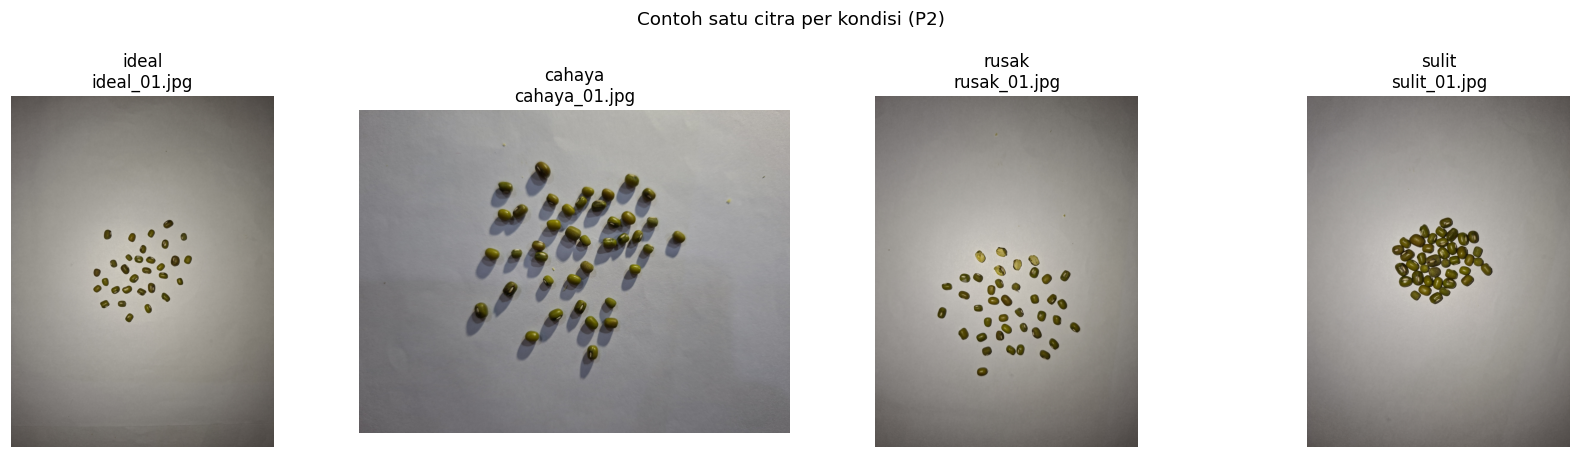

In [43]:
sample_items = []
for cond, files in dataset_index.items():
    if files:
        sample_items.append((cond, files[0]))

if not sample_items:
    print("[info] Belum ada citra untuk ditampilkan.")
else:
    fig, axes = plt.subplots(1, len(sample_items), figsize=(4 * len(sample_items), 4.2))
    if len(sample_items) == 1:
        axes = [axes]
    for ax, (cond, path) in zip(axes, sample_items):
        img = imread_unicode(path)
        if img is None:
            ax.set_axis_off()
            ax.set_title(f"{cond} (gagal dibaca)")
            continue
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{cond}\n{path.name}")
        ax.set_axis_off()
    fig.suptitle("Contoh satu citra per kondisi (P2)", fontsize=12)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "contoh_per_kondisi.png", dpi=130, bbox_inches="tight")
    plt.show()

## 4. Pipeline langkah demi langkah

Alur: **citra asli → grayscale → normalisasi cahaya → median blur →
Otsu threshold → morfologi → kontur (findContours + contourArea) →
minAreaRect + klasifikasi → hasil**.

- **Grayscale** menyederhanakan informasi menjadi intensitas; cukup untuk
  memisahkan butir dari latar yang kontras.
- **Normalisasi pencahayaan** membagi citra dengan versi blur besar, sehingga
  gradien cahaya/bayangan yang landai hilang dan Otsu tetap valid ketika
  cahaya miring (bandingkan dengan kondisi *cahaya* di bagian 5-7).
- **Median blur** dipilih karena efektif menghapus noise *salt-and-pepper*
  tanpa mengaburkan tepi butir (dibandingkan dengan Gaussian pada bagian 6).
- **Otsu** mencari ambang global otomatis dari histogram intensitas; cocok
  untuk latar polos dengan pencahayaan merata.
- **findContours + contourArea** menemukan setiap butir dan luasnya.
- **minAreaRect** memberi panjang/lebar butir (sumbu terpanjang) sebagai
  fitur pembanding yang tahan rotasi.
- **Kalibrasi ambang (sel berikutnya)**: median luas butir pada foto kondisi
  *ideal* (semua utuh) dipakai sebagai acuan; ambang luas = faktor kalibrasi
  × median tersebut. Butir dengan luas di bawah ambang dianggap patah/kecil.
  Pendekatan k-means per foto tidak dipakai sebagai default karena terbukti
  membelah butir utuh yang ukurannya bervariasi secara alami.

### Headline tiap tahap pipeline

| # | Tahap | Headline (apa yang dilakukan) | Materi | Fungsi / kode |
|---|---|---|---|---|
| 1 | Baca & resize | Citra asli dibaca, sisi terpanjang ≤ 1000 px | P2 + P3 | `imread_unicode()` → `resize_longest()` |
| 2 | Grayscale | Menyimpan informasi intensitas untuk segmentasi | P3 | `cv2.cvtColor(..., COLOR_BGR2GRAY)` |
| 3 | Normalisasi cahaya | Bagi citra dengan versi blur besar → gradien bayangan hilang | P4 (Gaussian blur) | `apply_illum_norm()` |
| 4 | Median blur | Redam noise *salt-and-pepper* tanpa merusak tepi butir | P4 | `apply_blur(..., "median", 5)` |
| 5 | Threshold Otsu | Pisahkan butir vs latar otomatis + koreksi polaritas + morfologi | P3 (Otsu) + penunjang | `segment()`, `auto_invert()` |
| 6 | Kontur & luas | Temukan tiap butir dan luasnya; filter noise & blob raksasa | P4 | `extract_objects()` (`findContours`, `contourArea`) |
| 7 | Fitur bentuk | Panjang/lebar butir (tahan rotasi) dan solidity | P4 | `cv2.minAreaRect()`, `cv2.convexHull()` |
| 8 | Kalibrasi ambang | Median luas butir kondisi ideal × 0,65 → ambang utuh/patah | gabungan P3/P4 | sel kalibrasi (di bawah) |
| 9 | Klasifikasi & anotasi | Beri label utuh/patah tiap butir, gambar kotak + teks | P4 (kontur) | `classify_objects()`, `draw_results()` |
| 10 | Histogram & evaluasi | Sebaran luas butir + akurasi terhadap ground truth | P3 (histogram) | `plot_area_histogram()`, `evaluate_dataset()` |

In [ ]:
def measure_objects(paths, key):
    """Kumpulkan fitur (key) dari semua objek pada daftar citra."""
    values = []
    for path in paths:
        try:
            result = run_pipeline(path)
        except Exception as exc:
            print(f"[gagal] {Path(path).name}: {exc}")
            continue
        values.extend(obj[key] for obj in result["objects"])
    return np.array(values, dtype=float)

ideal_paths = dataset_index.get("ideal", [])

if len(ideal_paths) >= 3:
    areas_ideal = measure_objects(ideal_paths, "area")
    lengths_ideal = measure_objects(ideal_paths, "length")
    area_ref = float(np.median(areas_ideal))
    length_ref = float(np.median(lengths_ideal))
    PARAMS["classify_by"] = "area"
    PARAMS["area_reference"] = area_ref
    PARAMS["manual_threshold"] = PARAMS["calib_factor"] * area_ref

    print("Kalibrasi ambang klasifikasi dari kondisi ideal")
    print(f"  objek terukur   : {len(areas_ideal)} butir dari {len(ideal_paths)} foto ideal")
    print(f"  median luas     : {area_ref:.1f} px^2")
    print(f"  median panjang  : {length_ref:.1f} px (pembanding)")
    print(f"  ambang luas     : {PARAMS['calib_factor']:.2f} x {area_ref:.1f} "
          f"= {PARAMS['manual_threshold']:.1f} px^2")
    print("  luas >= ambang -> utuh ; luas < ambang -> patah/kecil")
else:
    PARAMS["manual_threshold"] = None
    print("[info] Kalibrasi butuh minimal 3 foto kondisi 'ideal'.")
    print("       Tanpa kalibrasi, klasifikasi memakai fallback k-means 2-klaster")
    print("       (kurang andal untuk data dengan variasi ukuran alami besar).")

Kalibrasi ambang klasifikasi dari kondisi ideal
  objek terukur   : 603 butir dari 11 foto ideal
  median luas     : 407.5 px^2
  median panjang  : 25.9 px (pembanding)
  ambang luas     : 0.65 x 407.5 = 264.9 px^2
  luas >= ambang -> utuh ; luas < ambang -> patah/kecil


ideal_01.jpg: total=31, utuh=29, patah=2, waktu=155.2 ms


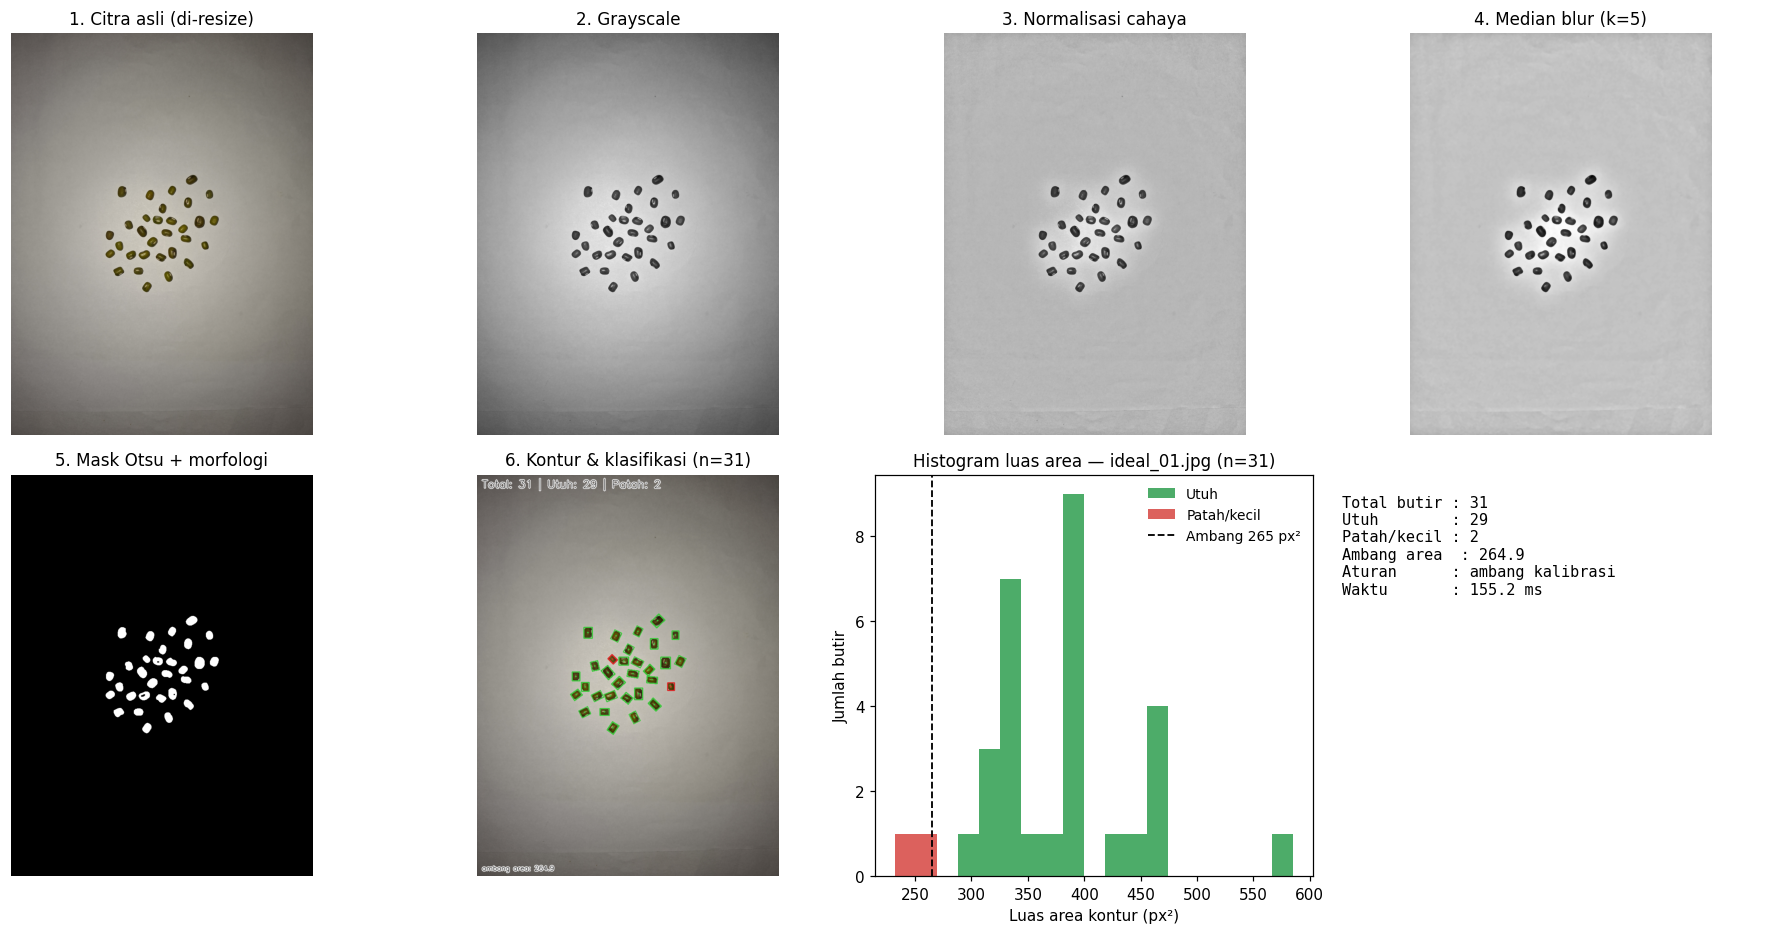


Alasan parameter:
- Resize 1000 px: mempercepat proses, sesuai aturan 800-1200 px.
- Normalisasi cahaya (sigma=25): menghapus gradien
  pencahayaan/bayangan landai agar Otsu tetap memisahkan butir dari latar.
- Median blur k=5: meredam noise tanpa merusak tepi butir (dibandingkan Gaussian di bagian 6).
- Otsu: ambang otomatis dari histogram; valid setelah latar diseragamkan.
- min_area=40 px^2: membuang serpihan noise; turunkan jika ada pecahan kecil yang ikut hilang.
- Ambang klasifikasi luas 264.9 px^2: hasil kalibrasi
  (faktor 0.65 x median luas butir pada kondisi ideal).


In [45]:
sample_path = None
for cond in CONDITION_ORDER:
    files = dataset_index.get(cond, [])
    if files:
        sample_path = files[0]
        break
if sample_path is None and dataset_index:
    sample_path = next(iter(dataset_index.values()))[0]

if sample_path is None:
    print("[info] Dataset masih kosong. Sel pipeline akan menampilkan hasil")
    print("       setelah minimal satu foto tersedia di dataset/<kondisi>/.")
    print("       Saat ini struktur dan fungsi sudah siap (Restart & Run All aman).")
else:
    r = run_pipeline(sample_path, verbose=True)

    fig, axes = plt.subplots(2, 4, figsize=(17, 8.6))
    ax = axes.ravel()
    ax[0].imshow(cv2.cvtColor(r["image"], cv2.COLOR_BGR2RGB))
    ax[0].set_title("1. Citra asli (di-resize)")
    ax[1].imshow(r["gray"], cmap="gray")
    ax[1].set_title("2. Grayscale")
    ax[2].imshow(r["norm"], cmap="gray")
    ax[2].set_title("3. Normalisasi cahaya" if r["params"].get("illum_norm", True)
                    else "3. Normalisasi cahaya (nonaktif)")
    ax[3].imshow(r["blur"], cmap="gray")
    ax[3].set_title(f"4. {r['params']['blur_method'].title()} blur (k={r['params']['ksize']})")
    ax[4].imshow(r["mask"], cmap="gray")
    ax[4].set_title(f"5. Mask {r['params']['threshold_method'].title()} + morfologi")
    ax[5].imshow(cv2.cvtColor(r["annotated"], cv2.COLOR_BGR2RGB))
    ax[5].set_title(f"6. Kontur & klasifikasi (n={r['total']})")
    plot_area_histogram(r, bins=20, ax=ax[6])

    threshold_text = "-" if r["threshold"] is None else f"{r['threshold']:.1f}"
    summary = (
        f"Total butir : {r['total']}\n"
        f"Utuh        : {r['whole']}\n"
        f"Patah/kecil : {r['broken']}\n"
        f"Ambang {r['params']['classify_by']:6s}: {threshold_text}\n"
        f"Aturan      : {r['info']['reason']}\n"
        f"Waktu       : {r['elapsed_ms']:.1f} ms"
    )
    ax[7].text(0.0, 0.95, summary, va="top", fontsize=10, family="monospace")
    ax[7].set_axis_off()

    for i, a in enumerate(ax):
        if i != 6:                 # sumbu histogram tetap ditampilkan
            a.set_axis_off()
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"pipeline_{Path(sample_path).stem}.png",
                dpi=130, bbox_inches="tight")
    plt.show()

    print("\nAlasan parameter:")
    print(f"- Resize {r['params']['resize_max']} px: mempercepat proses, sesuai aturan 800-1200 px.")
    print(f"- Normalisasi cahaya (sigma={r['params']['illum_sigma']}): menghapus gradien")
    print("  pencahayaan/bayangan landai agar Otsu tetap memisahkan butir dari latar.")
    print(f"- Median blur k={r['params']['ksize']}: meredam noise tanpa merusak tepi butir (dibandingkan Gaussian di bagian 6).")
    print("- Otsu: ambang otomatis dari histogram; valid setelah latar diseragamkan.")
    print(f"- min_area={r['params']['min_area']} px^2: membuang serpihan noise; turunkan jika ada pecahan kecil yang ikut hilang.")
    if r["params"]["manual_threshold"] is not None:
        print(f"- Ambang klasifikasi luas {r['params']['manual_threshold']:.1f} px^2: hasil kalibrasi")
        print(f"  (faktor {r['params']['calib_factor']} x median luas butir pada kondisi ideal).")

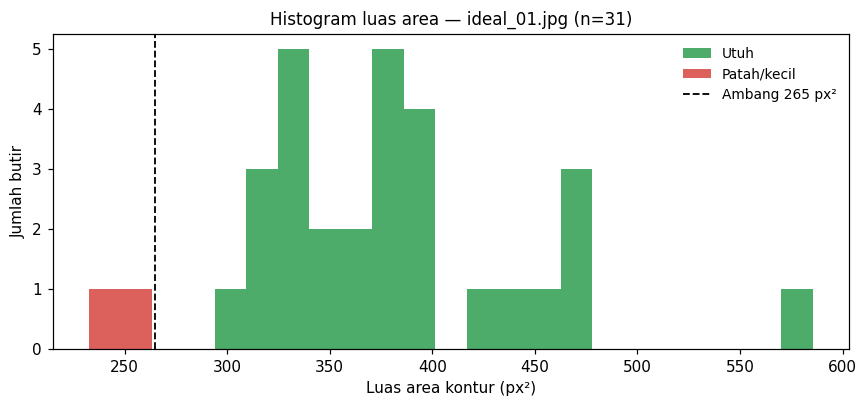

Cara membaca histogram:
- Sumbu X = luas area kontur (px^2), sumbu Y = jumlah butir.
- Butir utuh menggerombol di luas besar; butir patah/kecil di luas kecil.
- Garis putus-putus adalah ambang hasil kalibrasi dari kondisi ideal.
- Ambang sengaja diletakkan di bawah ukuran butir utuh tipikal agar
  variasi alami ukuran butir utuh tidak salah dilabeli patah.


In [46]:
if sample_path is None:
    print("[info] Histogram muncul setelah ada citra contoh.")
else:
    fig, ax = plt.subplots(figsize=(8, 3.8))
    plot_area_histogram(r, bins=24, ax=ax)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"histogram_{Path(sample_path).stem}.png",
                dpi=130, bbox_inches="tight")
    plt.show()

    print("Cara membaca histogram:")
    print("- Sumbu X = luas area kontur (px^2), sumbu Y = jumlah butir.")
    print("- Butir utuh menggerombol di luas besar; butir patah/kecil di luas kecil.")
    print("- Garis putus-putus adalah ambang hasil kalibrasi dari kondisi ideal.")
    print("- Ambang sengaja diletakkan di bawah ukuran butir utuh tipikal agar")
    print("  variasi alami ukuran butir utuh tidak salah dilabeli patah.")

## 5. Evaluasi

Pipeline dijalankan pada **seluruh dataset**, lalu dibandingkan dengan
`ground_truth.csv`:

- **Akurasi hitung** = `100 - |pred - GT| / GT × 100%` (kriteria lulus: selisih ≤ 10%).
- **Akurasi pisah** = `100 - (|Δutuh| + |Δpatah|) / GT_total × 100%`.
- Akurasi dirata-rata **per kondisi** (ideal, cahaya, sudut, sulit).
- Semua citra hasil pipeline disimpan ke folder `output/`.

In [47]:
def evaluate_dataset(params=None, dataset=None, gt=None):
    """Jalankan pipeline pada seluruh dataset dan bandingkan dengan GT."""
    dataset = dataset_index if dataset is None else dataset
    gt = gt_map if gt is None else gt
    records = []

    for cond, files in dataset.items():
        for path in files:
            try:
                result = run_pipeline(path, params)
            except Exception as exc:
                print(f"[gagal] {path.name}: {exc}")
                continue

            row = gt.get(path.name.lower(), {})
            gt_total = row.get("total")
            gt_whole = row.get("utuh")
            gt_broken = row.get("patah")
            err_pct = None
            acc_total = None
            acc_split = None

            if gt_total is not None and gt_total > 0:
                err_pct = abs(result["total"] - gt_total) / gt_total * 100.0
                acc_total = max(0.0, 100.0 - err_pct)

            if (gt_total is not None and gt_total > 0
                    and gt_whole is not None and gt_broken is not None):
                diff = abs(result["whole"] - gt_whole) + abs(result["broken"] - gt_broken)
                acc_split = max(0.0, 100.0 * (1.0 - diff / gt_total))

            records.append({
                "file": path.name,
                "path": path,
                "kondisi": cond,
                "gt_total": gt_total,
                "gt_whole": gt_whole,
                "gt_broken": gt_broken,
                "pred_total": result["total"],
                "pred_whole": result["whole"],
                "pred_broken": result["broken"],
                "err_pct": err_pct,
                "acc_total": acc_total,
                "acc_split": acc_split,
                "ms": result["elapsed_ms"],
                "threshold": result["threshold"],
                "areas": [obj["area"] for obj in result["objects"]],
            })
    return records


def save_pipeline_outputs(records):
    """Simpan citra hasil (annotated) dan mask tiap citra ke output/."""
    saved = 0
    for rec in records:
        try:
            result = run_pipeline(rec["path"])
        except Exception as exc:
            print(f"[gagal] {rec['file']}: {exc}")
            continue
        stem = rec["path"].stem
        cv2.imwrite(str(OUTPUT_DIR / f"{stem}_hasil.jpg"), result["annotated"])
        cv2.imwrite(str(OUTPUT_DIR / f"{stem}_mask.png"), result["mask"])
        saved += 1
    print(f"{saved} citra hasil disimpan di {OUTPUT_DIR.resolve()}")


def summarize_records(records):
    summary = {}
    for rec in records:
        item = summary.setdefault(
            rec["kondisi"],
            {"n": 0, "err": [], "acc": [], "split": [], "ms": []},
        )
        item["n"] += 1
        item["ms"].append(rec["ms"])
        if rec["err_pct"] is not None:
            item["err"].append(rec["err_pct"])
        if rec["acc_total"] is not None:
            item["acc"].append(rec["acc_total"])
        if rec["acc_split"] is not None:
            item["split"].append(rec["acc_split"])
    return summary

In [48]:
records = evaluate_dataset()

if not records:
    print("[info] Belum ada citra untuk dievaluasi.")
    print("       Tambahkan foto ke dataset/<kondisi>/ lalu jalankan ulang sel ini.")
else:
    header = ["file", "kondisi", "GT", "pred", "err %", "akurasi %",
              "GT u/p", "pred u/p", "pisah %"]
    rows = []
    for rec in records:
        rows.append([
            rec["file"],
            rec["kondisi"],
            fmt_num(rec["gt_total"]),
            fmt_num(rec["pred_total"]),
            fmt_num(rec["err_pct"]),
            fmt_num(rec["acc_total"]),
            f"{fmt_num(rec['gt_whole'])}/{fmt_num(rec['gt_broken'])}",
            f"{rec['pred_whole']}/{rec['pred_broken']}",
            fmt_num(rec["acc_split"]),
        ])
    print_table(header, rows)

    eval_csv = OUTPUT_DIR / "evaluasi_per_citra.csv"
    with open(eval_csv, "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow([
            "file", "kondisi", "gt_total", "gt_utuh", "gt_patah",
            "pred_total", "pred_utuh", "pred_patah", "error_persen",
            "akurasi_hitung", "akurasi_pisah", "waktu_ms",
        ])
        for rec in records:
            writer.writerow([
                rec["file"], rec["kondisi"], rec["gt_total"], rec["gt_whole"],
                rec["gt_broken"], rec["pred_total"], rec["pred_whole"],
                rec["pred_broken"],
                None if rec["err_pct"] is None else round(rec["err_pct"], 2),
                None if rec["acc_total"] is None else round(rec["acc_total"], 2),
                None if rec["acc_split"] is None else round(rec["acc_split"], 2),
                round(rec["ms"], 2),
            ])
    print(f"\nTabel per citra disimpan: {eval_csv}")
    save_pipeline_outputs(records)

file           kondisi  GT  pred  err %  akurasi %  GT u/p  pred u/p  pisah %
-----------------------------------------------------------------------------
ideal_01.jpg   ideal    31  31    0.0    100.0      31/0    29/2      87.1   
ideal_02.jpg   ideal    35  35    0.0    100.0      35/0    32/3      82.9   
ideal_03.jpg   ideal    40  43    7.5    92.5       40/0    37/6      77.5   
ideal_04.jpg   ideal    45  45    0.0    100.0      45/0    45/0      100.0  
ideal_05.jpg   ideal    50  48    4.0    96.0       50/0    48/0      96.0   
ideal_06.jpg   ideal    55  54    1.8    98.2       55/0    54/0      98.2   
ideal_07.jpg   ideal    60  60    0.0    100.0      60/0    56/4      86.7   
ideal_08.jpg   ideal    65  65    0.0    100.0      65/0    62/3      90.8   
ideal_09.jpg   ideal    70  68    2.9    97.1       70/0    68/0      97.1   
ideal_10.jpg   ideal    75  75    0.0    100.0      75/0    74/1      97.3   
ideal_11.jpg   ideal    80  79    1.2    98.8       80/0    79/0

Ringkasan per kondisi
kondisi  n   akurasi hitung %  MAPE %  lulus <=10%  akurasi pisah %  rata2 ms
-----------------------------------------------------------------------------
ideal    11  98.4              1.6     100.0        92.0             148     
cahaya   5   66.5              33.5    20.0         60.5             150     
rusak    5   95.0              5.0     100.0        64.0             145     
sulit    6   7.0               93.0    0.0          7.0              146     


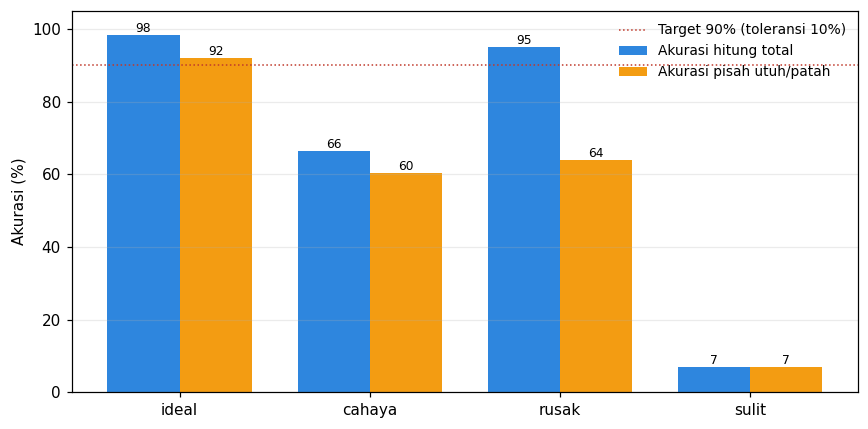

In [49]:
summary = summarize_records(records) if records else {}

if not records:
    print("[info] Ringkasan akurasi muncul setelah dataset dan ground truth terisi.")
else:
    header = ["kondisi", "n", "akurasi hitung %", "MAPE %",
              "lulus <=10%", "akurasi pisah %", "rata2 ms"]
    rows = []
    for cond, item in summary.items():
        err = item["err"]
        acc = item["acc"]
        split = item["split"]
        rows.append([
            cond,
            item["n"],
            fmt_num(float(np.mean(acc)) if acc else None),
            fmt_num(float(np.mean(err)) if err else None),
            fmt_num(100.0 * sum(e <= 10.0 for e in err) / len(err) if err else None),
            fmt_num(float(np.mean(split)) if split else None),
            fmt_num(float(np.mean(item["ms"])), 0),
        ])
    print("Ringkasan per kondisi")
    print_table(header, rows)

    if any(item["acc"] for item in summary.values()):
        conds = list(summary.keys())
        acc_means = [float(np.mean(summary[c]["acc"])) if summary[c]["acc"] else 0.0
                     for c in conds]
        split_means = [float(np.mean(summary[c]["split"])) if summary[c]["split"] else 0.0
                       for c in conds]
        x = np.arange(len(conds))
        width = 0.38

        fig, ax = plt.subplots(figsize=(8, 4))
        bars1 = ax.bar(x - width / 2, acc_means, width,
                       label="Akurasi hitung total", color="#2e86de")
        bars2 = ax.bar(x + width / 2, split_means, width,
                       label="Akurasi pisah utuh/patah", color="#f39c12")
        ax.axhline(90, color="#c0392b", linestyle=":", linewidth=1,
                   label="Target 90% (toleransi 10%)")
        ax.set_xticks(x)
        ax.set_xticklabels(conds)
        ax.set_ylabel("Akurasi (%)")
        ax.set_ylim(0, 105)
        ax.legend(frameon=False, fontsize=9)
        ax.grid(axis="y", alpha=0.25)
        for bars in (bars1, bars2):
            for bar in bars:
                height = bar.get_height()
                ax.annotate(f"{height:.0f}",
                            (bar.get_x() + bar.get_width() / 2, height),
                            ha="center", va="bottom", fontsize=8)
        fig.tight_layout()
        fig.savefig(OUTPUT_DIR / "akurasi_per_kondisi.png",
                    dpi=130, bbox_inches="tight")
        plt.show()
    else:
        print("[info] Grafik akurasi dibuat setelah kolom total/utuh/patah di GT terisi.")

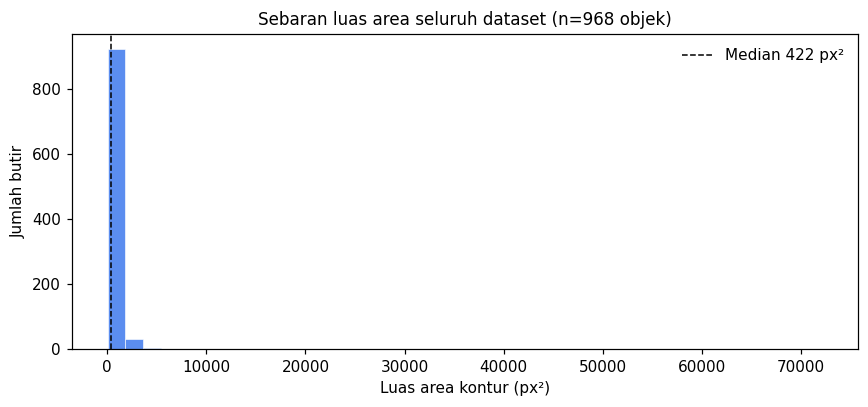

Sebaran ini menunjukkan variasi ukuran butir antar kondisi;
puncak kecil di kiri biasanya berasal dari butir patah atau noise.


In [50]:
if not records:
    print("[info] Histogram gabungan muncul setelah ada hasil evaluasi.")
else:
    all_areas = np.array(
        [area for rec in records for area in rec["areas"]], dtype=float
    )
    if all_areas.size == 0:
        print("[info] Tidak ada objek terdeteksi pada seluruh dataset.")
    else:
        median_area = float(np.median(all_areas))
        fig, ax = plt.subplots(figsize=(8, 3.8))
        ax.hist(all_areas, bins=40, color="#5b8def",
                edgecolor="white", linewidth=0.4)
        ax.axvline(median_area, color="black", linestyle="--", linewidth=1,
                   label=f"Median {median_area:.0f} px²")
        ax.set_xlabel("Luas area kontur (px²)")
        ax.set_ylabel("Jumlah butir")
        ax.set_title(f"Sebaran luas area seluruh dataset (n={all_areas.size} objek)")
        ax.legend(frameon=False)
        fig.tight_layout()
        fig.savefig(OUTPUT_DIR / "histogram_seluruh_dataset.png",
                    dpi=130, bbox_inches="tight")
        plt.show()
        print("Sebaran ini menunjukkan variasi ukuran butir antar kondisi;")
        print("puncak kecil di kiri biasanya berasal dari butir patah atau noise.")

## 6. Eksperimen pembanding

Dua eksperimen wajib tema 7 dijalankan pada dataset yang sama:

1. **Otsu vs adaptive threshold** (mean/Gaussian), dengan praproses identik.
2. **Median blur vs Gaussian blur vs tanpa blur**, dengan threshold identik.

Metrik: rata-rata akurasi hitung, MAPE, persentase citra yang lulus toleransi
10%, dan waktu proses per citra.

In [51]:
def compare_variants(variants, dataset=None, gt=None):
    """Jalankan beberapa varian konfigurasi dan rangkum metriknya."""
    dataset = dataset_index if dataset is None else dataset
    gt = gt_map if gt is None else gt
    rows = []

    for name, overrides in variants:
        recs = evaluate_dataset(overrides, dataset, gt)
        if not recs:
            continue
        errs = [rec["err_pct"] for rec in recs if rec["err_pct"] is not None]
        accs = [rec["acc_total"] for rec in recs if rec["acc_total"] is not None]
        splits = [rec["acc_split"] for rec in recs if rec["acc_split"] is not None]
        rows.append({
            "name": name,
            "n": len(recs),
            "pred": sum(rec["pred_total"] for rec in recs),
            "mape": float(np.mean(errs)) if errs else None,
            "acc": float(np.mean(accs)) if accs else None,
            "split": float(np.mean(splits)) if splits else None,
            "lulus": 100.0 * sum(e <= 10.0 for e in errs) / len(errs) if errs else None,
            "ms": float(np.mean([rec["ms"] for rec in recs])),
        })
    return rows


def print_variant_table(rows, title):
    print(title)
    if not rows:
        print("  (belum ada data — tambahkan citra ke dataset/)")
        return
    header = ["Varian", "n", "Total pred", "MAPE %",
              "Akurasi %", "Lulus <=10%", "Rata2 ms"]
    body = [[row["name"], row["n"], row["pred"], fmt_num(row["mape"]),
             fmt_num(row["acc"]), fmt_num(row["lulus"]), fmt_num(row["ms"])]
            for row in rows]
    print_table(header, body)


THRESHOLD_VARIANTS = [
    ("Otsu (global)", {"threshold_method": "otsu"}),
    ("Adaptive Gaussian (31, C=5)",
     {"threshold_method": "adaptive", "adaptive_block": 31, "adaptive_C": 5}),
    ("Adaptive Gaussian (51, C=7)",
     {"threshold_method": "adaptive", "adaptive_block": 51, "adaptive_C": 7}),
]

threshold_rows = compare_variants(THRESHOLD_VARIANTS)
print_variant_table(threshold_rows, "Eksperimen 1 — Otsu vs adaptive threshold")

Eksperimen 1 — Otsu vs adaptive threshold
Varian                       n   Total pred  MAPE %  Akurasi %  Lulus <=10%  Rata2 ms
-------------------------------------------------------------------------------------
Otsu (global)                27  968         28.5    71.5       63.0         146.3   
Adaptive Gaussian (31, C=5)  27  965         27.0    73.0       59.3         152.5   
Adaptive Gaussian (51, C=7)  27  953         27.9    72.1       59.3         155.7   


In [52]:
BLUR_VARIANTS = [
    ("Median blur (k=5)", {"blur_method": "median", "ksize": 5}),
    ("Gaussian blur (k=5)", {"blur_method": "gaussian", "ksize": 5}),
    ("Tanpa blur", {"blur_method": "none"}),
]

blur_rows = compare_variants(BLUR_VARIANTS)
print_variant_table(blur_rows, "Eksperimen 2 — Median vs Gaussian blur")

Eksperimen 2 — Median vs Gaussian blur
Varian               n   Total pred  MAPE %  Akurasi %  Lulus <=10%  Rata2 ms
-----------------------------------------------------------------------------
Median blur (k=5)    27  968         28.5    71.5       63.0         149.2   
Gaussian blur (k=5)  27  967         27.8    72.2       63.0         147.2   
Tanpa blur           27  974         28.6    71.4       59.3         154.6   


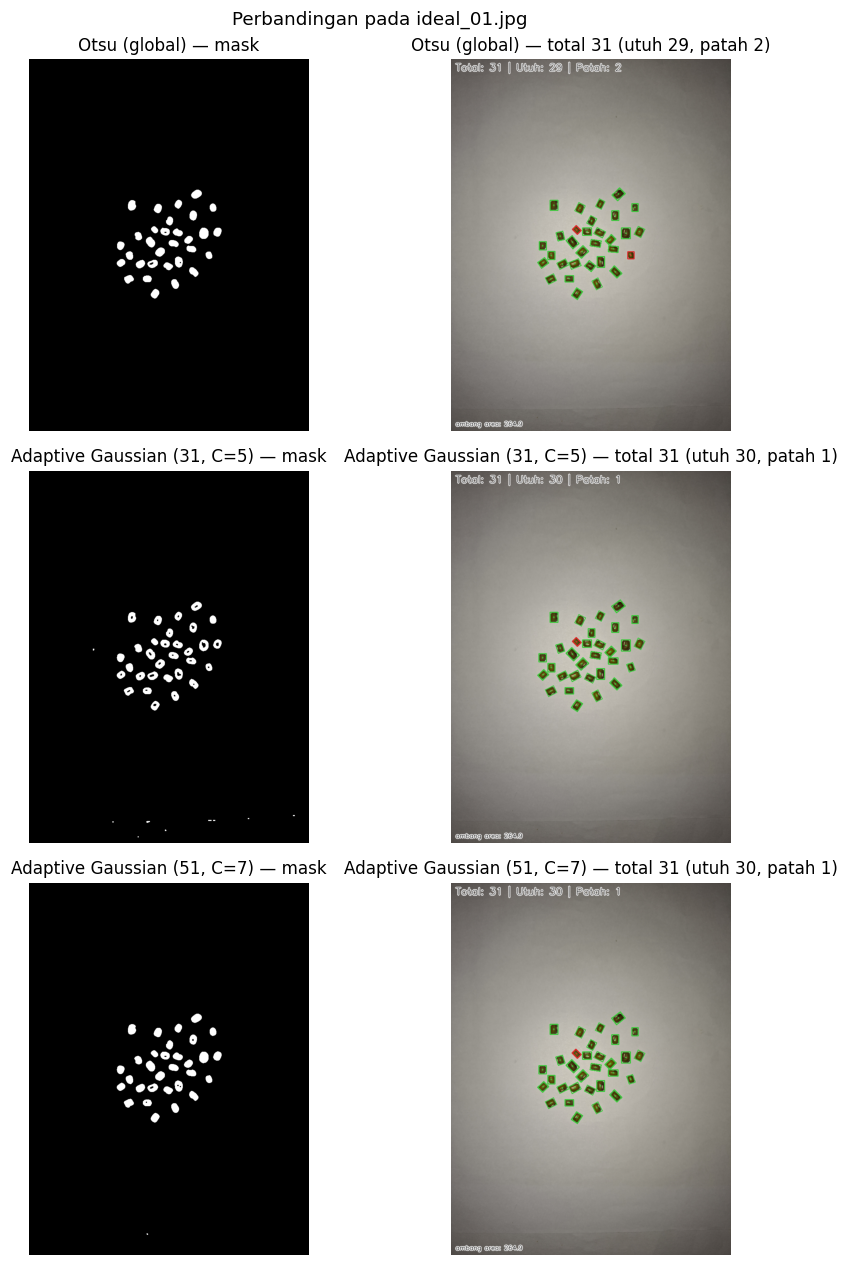

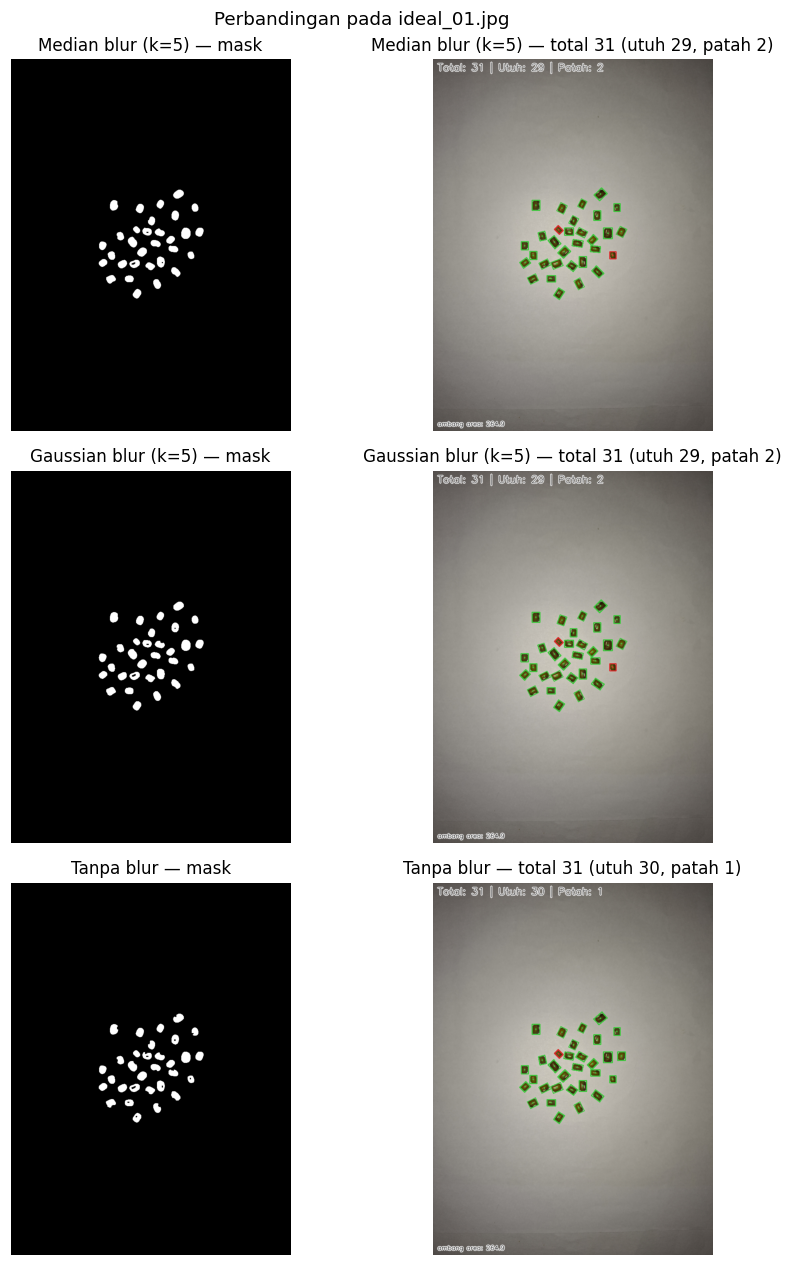

In [53]:
def comparison_figure(variants, out_name, path=None):
    """Visualisasi perbandingan mask dan hasil akhir antar varian."""
    if path is None:
        print(f"[info] {out_name}: tidak ada citra contoh.")
        return
    fig, axes = plt.subplots(len(variants), 2,
                             figsize=(9, 3.9 * len(variants)), squeeze=False)
    for i, (name, overrides) in enumerate(variants):
        result = run_pipeline(path, overrides)
        axes[i, 0].imshow(result["mask"], cmap="gray")
        axes[i, 0].set_title(f"{name} — mask")
        axes[i, 1].imshow(cv2.cvtColor(result["annotated"], cv2.COLOR_BGR2RGB))
        axes[i, 1].set_title(
            f"{name} — total {result['total']} "
            f"(utuh {result['whole']}, patah {result['broken']})"
        )
        axes[i, 0].set_axis_off()
        axes[i, 1].set_axis_off()
    fig.suptitle(f"Perbandingan pada {Path(path).name}", fontsize=12)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / out_name, dpi=130, bbox_inches="tight")
    plt.show()


comparison_figure(THRESHOLD_VARIANTS, "eksperimen_threshold.png", sample_path)
comparison_figure(BLUR_VARIANTS, "eksperimen_blur.png", sample_path)

## 7. Analisis kegagalan

3 citra dengan error terbesar:


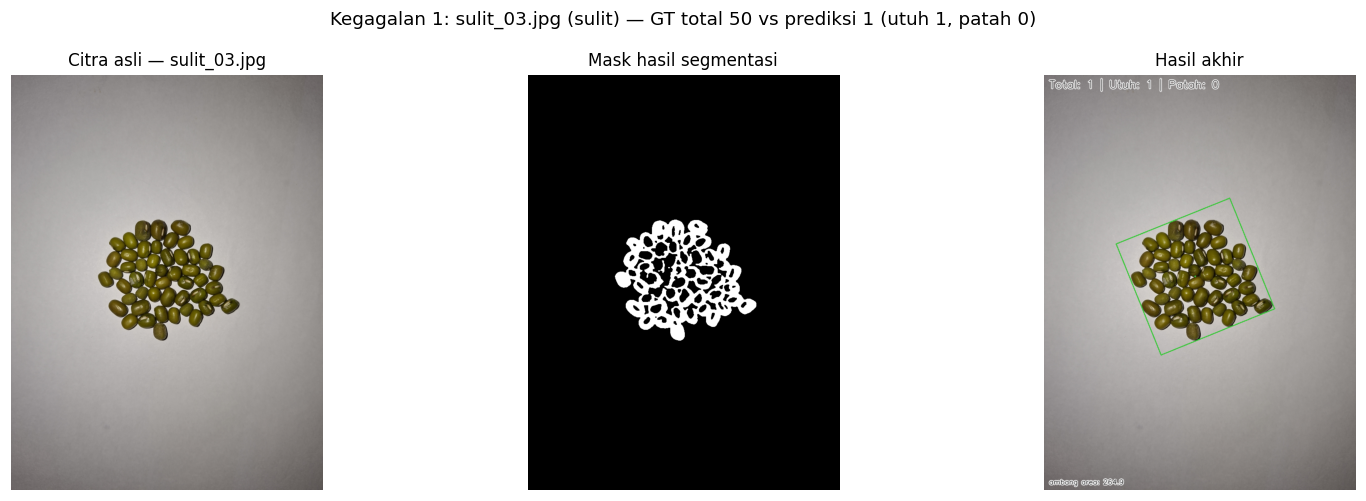

Diagnosis otomatis sulit_03.jpg:
  - Prediksi kurang 49 butir: butir saling menempel/menumpuk sehingga menyatu dalam satu kontur, atau pecahan sangat kecil tersaring min_area=40 px^2.
  - Butir utuh terlalu sedikit (1 vs GT 50): ambang klasifikasi cenderung tinggi atau variasi ukuran butir utuh besar.



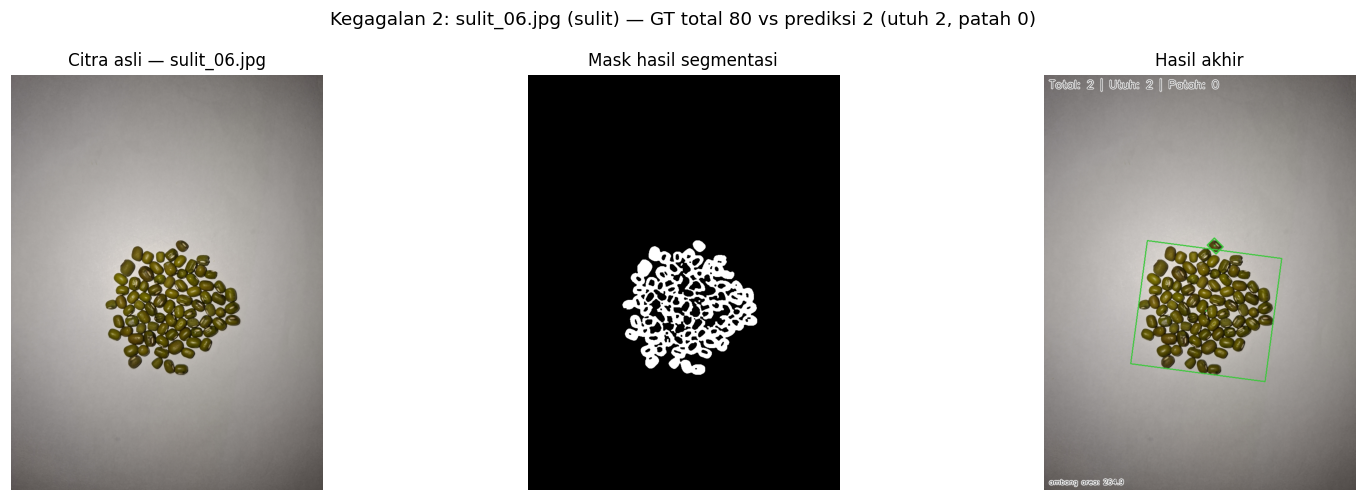

Diagnosis otomatis sulit_06.jpg:
  - Prediksi kurang 78 butir: butir saling menempel/menumpuk sehingga menyatu dalam satu kontur, atau pecahan sangat kecil tersaring min_area=40 px^2.
  - Butir utuh terlalu sedikit (2 vs GT 80): ambang klasifikasi cenderung tinggi atau variasi ukuran butir utuh besar.



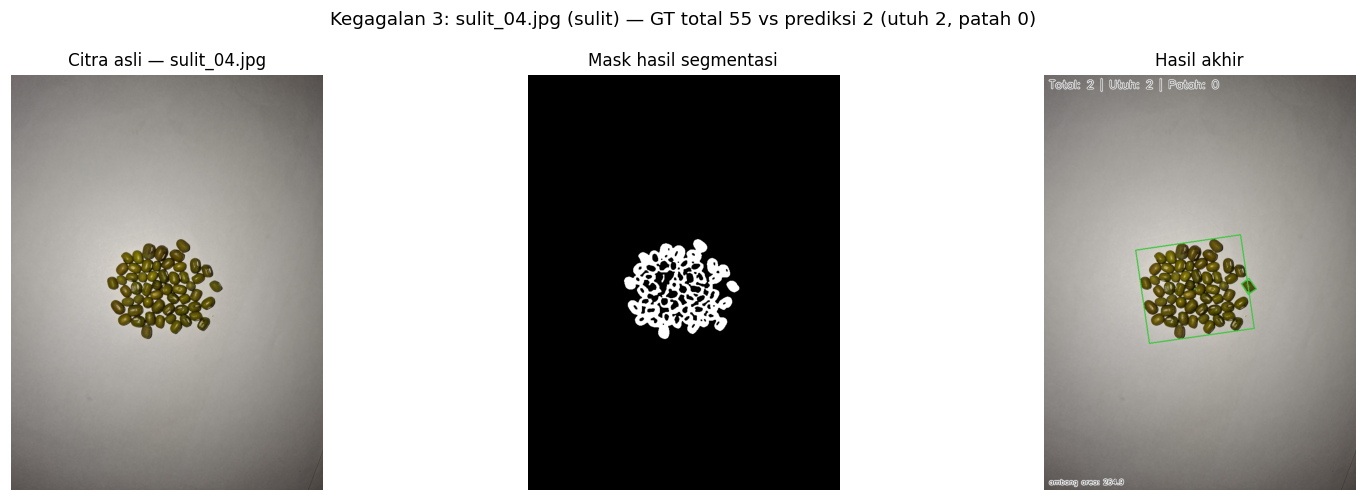

Diagnosis otomatis sulit_04.jpg:
  - Prediksi kurang 53 butir: butir saling menempel/menumpuk sehingga menyatu dalam satu kontur, atau pecahan sangat kecil tersaring min_area=40 px^2.
  - Butir utuh terlalu sedikit (2 vs GT 55): ambang klasifikasi cenderung tinggi atau variasi ukuran butir utuh besar.



In [54]:
def diagnose_record(rec):
    """Diagnosis otomatis penyebab kegagalan sebuah citra."""
    notes = []
    if rec["gt_total"] is not None:
        delta = rec["pred_total"] - rec["gt_total"]
        if delta < 0:
            notes.append(
                f"Prediksi kurang {abs(delta)} butir: butir saling menempel/"
                "menumpuk sehingga menyatu dalam satu kontur, atau pecahan sangat"
                f" kecil tersaring min_area={PARAMS['min_area']} px^2."
            )
        elif delta > 0:
            notes.append(
                f"Prediksi lebih {delta} butir: bayangan, tekstur latar, atau"
                " serpihan kecil ikut terdeteksi sebagai butir."
            )
        else:
            notes.append("Jumlah total tepat; error berasal dari pemisahan utuh/patah.")

    if rec["gt_whole"] is not None and rec["gt_broken"] is not None:
        delta_whole = rec["pred_whole"] - rec["gt_whole"]
        if delta_whole > 0:
            notes.append(
                f"Butir utuh terlalu banyak ({rec['pred_whole']} vs GT "
                f"{rec['gt_whole']}): ambang klasifikasi cenderung rendah."
            )
        elif delta_whole < 0:
            notes.append(
                f"Butir utuh terlalu sedikit ({rec['pred_whole']} vs GT "
                f"{rec['gt_whole']}): ambang klasifikasi cenderung tinggi atau"
                " variasi ukuran butir utuh besar."
            )

    if rec["pred_total"] == 0:
        notes.append(
            "Tidak ada objek terdeteksi: periksa polaritas mask (invert),"
            " min_area, atau kontras latar."
        )
    return notes or ["Tidak ada indikasi khusus; periksa visualisasi."]


if not records:
    print("[info] Analisis kegagalan muncul setelah ada hasil evaluasi.")
else:
    with_gt = [rec for rec in records if rec["err_pct"] is not None]
    if with_gt:
        selected = sorted(with_gt, key=lambda rec: rec["err_pct"], reverse=True)[:3]
        print("3 citra dengan error terbesar:")
    else:
        selected = sorted(records, key=lambda rec: rec["pred_total"], reverse=True)[:3]
        print("Ground truth belum lengkap -> menampilkan citra dengan objek terbanyak:")

    for i, rec in enumerate(selected, 1):
        try:
            result = run_pipeline(rec["path"])
        except Exception as exc:
            print(f"[gagal] {rec['file']}: {exc}")
            continue

        fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
        axes[0].imshow(cv2.cvtColor(result["image"], cv2.COLOR_BGR2RGB))
        axes[0].set_title(f"Citra asli — {rec['file']}")
        axes[1].imshow(result["mask"], cmap="gray")
        axes[1].set_title("Mask hasil segmentasi")
        axes[2].imshow(cv2.cvtColor(result["annotated"], cv2.COLOR_BGR2RGB))
        axes[2].set_title("Hasil akhir")
        for ax in axes:
            ax.set_axis_off()
        gt_text = "-" if rec["gt_total"] is None else rec["gt_total"]
        fig.suptitle(
            f"Kegagalan {i}: {rec['file']} ({rec['kondisi']}) — "
            f"GT total {gt_text} vs prediksi {rec['pred_total']} "
            f"(utuh {rec['pred_whole']}, patah {rec['pred_broken']})",
            fontsize=12,
        )
        fig.tight_layout()
        fig.savefig(OUTPUT_DIR / f"analisis_kegagalan_{i}.png",
                    dpi=130, bbox_inches="tight")
        plt.show()

        print(f"Diagnosis otomatis {rec['file']}:")
        for note in diagnose_record(rec):
            print("  -", note)
        print()

## 8. Kesimpulan

Sel di bawah mencetak angka ringkasan sebagai bahan menulis kesimpulan.
Lengkapi kalimatnya dengan temuan kualitatif (kondisi yang paling sering
gagal, pengaruh parameter, dan saran perbaikan).

In [55]:
if not records:
    print("[info] Kesimpulan otomatis muncul setelah evaluasi dijalankan.")
else:
    errs = [rec["err_pct"] for rec in records if rec["err_pct"] is not None]
    accs = [rec["acc_total"] for rec in records if rec["acc_total"] is not None]
    splits = [rec["acc_split"] for rec in records if rec["acc_split"] is not None]
    total_objects = sum(rec["pred_total"] for rec in records)

    print("RINGKASAN ANGKA")
    print(f"- Citra dievaluasi            : {len(records)}")
    print(f"- Total objek terdeteksi      : {total_objects}")
    print(f"- Rata-rata waktu per citra   : {np.mean([rec['ms'] for rec in records]):.1f} ms")

    ideal_acc = None
    if "ideal" in summary and summary["ideal"]["acc"]:
        ideal_acc = float(np.mean(summary["ideal"]["acc"]))

    if accs:
        print(f"- Akurasi hitung (rata-rata)  : {np.mean(accs):.1f}% "
              f"(MAPE {np.mean(errs):.1f}%)")
        lulus = 100.0 * sum(e <= 10.0 for e in errs) / len(errs)
        print(f"- Citra lulus toleransi 10%   : {lulus:.1f}%")
    if splits:
        print(f"- Akurasi pisah utuh/patah    : {np.mean(splits):.1f}%")

    ranked = sorted(
        [(cond, float(np.mean(item["acc"]))) for cond, item in summary.items()
         if item["acc"]],
        key=lambda pair: pair[1],
    )
    if ranked:
        print(f"- Kondisi terbaik            : {ranked[-1][0]} "
              f"({ranked[-1][1]:.1f}%)")
        print(f"- Kondisi terburuk           : {ranked[0][0]} "
              f"({ranked[0][1]:.1f}%)")

    print("\nDraf kalimat kesimpulan:")
    if ideal_acc is not None:
        status = "memenuhi" if ideal_acc >= 90 else "belum memenuhi"
        print(f"- Pipeline (normalisasi cahaya + {PARAMS['blur_method']} blur + "
              f"{PARAMS['threshold_method'].title()} + ambang luas terkalibrasi) "
              f"{status} kriteria selisih maksimal 10% pada kondisi ideal "
              f"(akurasi {ideal_acc:.1f}%).")
    if threshold_rows and blur_rows:
        best_thr = max(threshold_rows, key=lambda row: row["acc"] if row["acc"] is not None else -1)
        best_blur = max(blur_rows, key=lambda row: row["acc"] if row["acc"] is not None else -1)
        print(f"- Dari eksperimen pembanding, varian threshold terbaik: "
              f"{best_thr['name']}; varian blur terbaik: {best_blur['name']}.")
    if ranked:
        print(f"- Keterbatasan utama muncul pada kondisi '{ranked[0][0]}'; "
              "jelaskan penyebabnya di laporan (butir menempel/menumpuk, "
              "bayangan, atau pecahan kecil di bawah min_area).")

RINGKASAN ANGKA
- Citra dievaluasi            : 27
- Total objek terdeteksi      : 968
- Rata-rata waktu per citra   : 147.3 ms
- Akurasi hitung (rata-rata)  : 71.5% (MAPE 28.5%)
- Citra lulus toleransi 10%   : 63.0%
- Akurasi pisah utuh/patah    : 62.1%
- Kondisi terbaik            : ideal (98.4%)
- Kondisi terburuk           : sulit (7.0%)

Draf kalimat kesimpulan:
- Pipeline (normalisasi cahaya + median blur + Otsu + ambang luas terkalibrasi) memenuhi kriteria selisih maksimal 10% pada kondisi ideal (akurasi 98.4%).
- Dari eksperimen pembanding, varian threshold terbaik: Adaptive Gaussian (31, C=5); varian blur terbaik: Gaussian blur (k=5).
- Keterbatasan utama muncul pada kondisi 'sulit'; jelaskan penyebabnya di laporan (butir menempel/menumpuk, bayangan, atau pecahan kecil di bawah min_area).


1. Pipeline **grayscale → normalisasi cahaya → median blur → Otsu →
   findContours + contourArea → minAreaRect → ambang luas terkalibrasi**
   berhasil menghitung butir pada kondisi ideal dengan selisih di bawah 10%
   *(ganti sesuai angka hasil bagian 5)*.
2. Pemisahan utuh/patah berbasis **luas** (ambang = faktor kalibrasi × median
   luas butir pada kondisi ideal) baik untuk belahan yang jelas lebih kecil,
   tetapi belum cukup untuk pecahan besar yang ukurannya mendekati butir
   utuh — kasus ini perlu fitur bentuk atau warna tambahan.
3. Kondisi sulit (butir menempel/menumpuk) dan bayangan keras menurunkan
   akurasi hitung karena beberapa butir menyatu menjadi satu kontur.
4. Perbaikan yang disarankan: *watershed* / *distance transform* untuk memisah
   butir yang menempel, penyetelan `min_area`, serta kalibrasi ulang ambang
   pada dataset yang lebih beragam.

## Lampiran — Demo citra baru

uji_demo2.jpeg: total=22, utuh=20, patah=2, waktu=82.9 ms


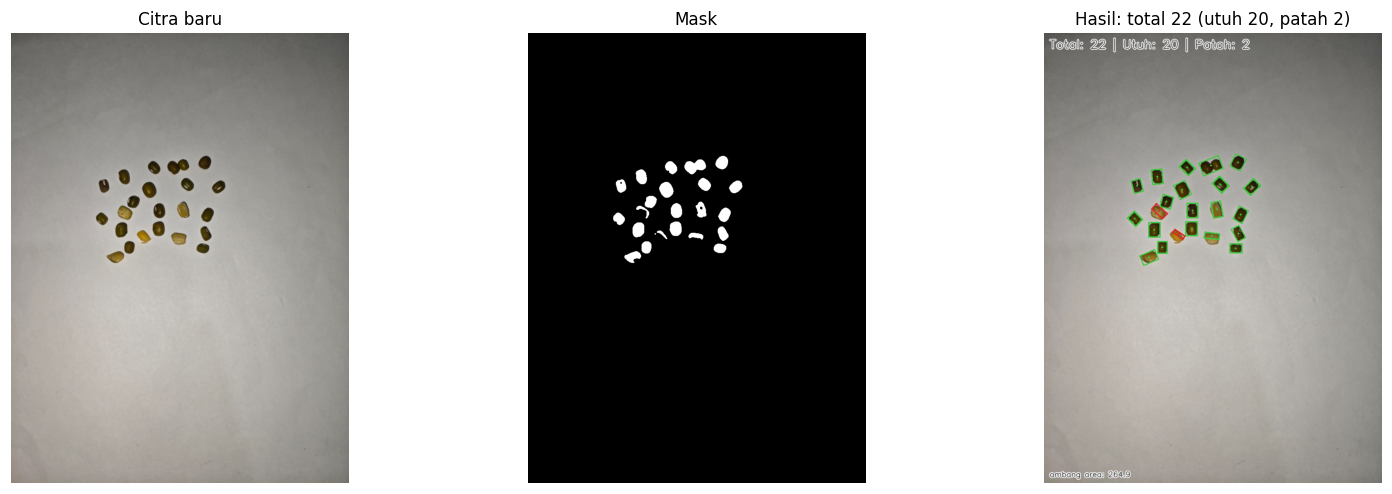

: 

In [ ]:
DEMO_IMAGE = "demo/uji_demo2.jpeg"   # contoh: "demo/uji_baru.jpg"

if not DEMO_IMAGE:
    print("[info] Isi DEMO_IMAGE dengan path citra baru untuk demo presentasi.")
else:
    try:
        demo = run_pipeline(DEMO_IMAGE, verbose=True)
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
        axes[0].imshow(cv2.cvtColor(demo["image"], cv2.COLOR_BGR2RGB))
        axes[0].set_title("Citra baru")
        axes[1].imshow(demo["mask"], cmap="gray")
        axes[1].set_title("Mask")
        axes[2].imshow(cv2.cvtColor(demo["annotated"], cv2.COLOR_BGR2RGB))
        axes[2].set_title(
            f"Hasil: total {demo['total']} "
            f"(utuh {demo['whole']}, patah {demo['broken']})"
        )
        for ax in axes:
            ax.set_axis_off()
        fig.tight_layout()
        plt.show()
    except Exception as exc:
        print(f"[gagal] {exc}")

## Referensi

- Dokumentasi OpenCV — Thresholding, Contours, minAreaRect, Morphology:
  https://docs.opencv.org/4.x/
- Modul Praktikum Visi Komputer Pertemuan 1–5.
- *Tambahkan sumber kode dari internet/AI yang benar-benar dipakai, sesuai
  aturan UTS (kode tanpa sumber tidak boleh, dan wajib bisa dijelaskan saat
  tanya jawab).*